# 02 · Quantization deep dive: from the formula to the deployed graph

Prerequisites (run once from the project root): `python -m src.train`, `python -m src.export_onnx`, `python -m src.quantize`
(or just `./run_all.sh`).

| Section | Interview question it prepares you for |
| --- | --- |
| 1. Affine quantization by hand | "Walk me through scale and zero-point." |
| 2. Input normalization | "Why normalize before quantizing?" |
| 3. BatchNorm folding | "What happens to BatchNorm at deployment?" |
| 4. Per-tensor vs per-channel weights | "Why per-channel for weights?" |
| 5. Activations and calibration | "Min-max vs percentile vs entropy?" |
| 6. Reading a QDQ ONNX graph | "What does a quantized ONNX model look like?" |
| 7. Accuracy, size, latency | "What did quantization cost you, and what did it buy?" |
| 8. Layer-by-layer comparison | "How do you find which layer breaks?" |

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
import torch, onnx
from src.data import SyntheticScans, make_scene, to_model_input, CLASS_NAMES, SCENE_RADIUS
from src.model import load_checkpoint
from src.metrics import sqnr_db
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

CKPT = Path("outputs/checkpoints/pointnet_seg.pt")
ONNX_DIR = Path("outputs/onnx")
assert CKPT.exists(), "Train first: python -m src.train"
model, ckpt = load_checkpoint(str(CKPT))
N = ckpt["n_points"]
print("checkpoint epoch", ckpt["epoch"], "val mIoU", round(ckpt["val"]["mIoU"], 3))

checkpoint epoch 8 val mIoU 0.825


## 1. Affine quantization by hand

A real value $x$ is stored as an integer $q$ with a **scale** $s$ (step size) and a **zero-point** $z$ (the integer that represents 0.0):

$$q = \mathrm{clamp}\big(\mathrm{round}(x/s) + z,\; q_{min},\; q_{max}\big) \qquad \hat{x} = s\,(q - z)$$

For a range $[x_{min}, x_{max}]$ and $b$ bits: $s = (x_{max} - x_{min}) / (2^b - 1)$, $z = \mathrm{round}(-x_{min}/s)$.

* **Asymmetric** (zero-point ≠ 0, usually uint8): uses the full range for skewed data such as post-ReLU activations.
* **Symmetric** (zero-point = 0, int8 in [-127, 127]): cheaper integer math; standard for weights.

Two error sources: **rounding** (at most s/2 inside the range) and **clipping** (values outside the range get clamped).

In [2]:
def qparams(xmin, xmax, bits=8, symmetric=False):
    xmin, xmax = min(xmin, 0.0), max(xmax, 0.0)            # 0.0 must be exactly representable
    if symmetric:
        qmax = 2 ** (bits - 1) - 1
        s = max(abs(xmin), abs(xmax)) / qmax
        return s, 0, -qmax, qmax
    qmin, qmax = 0, 2 ** bits - 1
    s = (xmax - xmin) / (qmax - qmin)
    z = int(round(qmin - xmin / s))
    return s, z, qmin, qmax

def quantize(x, s, z, qmin, qmax):
    return np.clip(np.round(x / s) + z, qmin, qmax).astype(np.int64)

def dequantize(q, s, z):
    return s * (q - z)

def fake_quant(x, xmin, xmax, bits=8, symmetric=False):
    s, z, lo, hi = qparams(xmin, xmax, bits, symmetric)
    return dequantize(quantize(x, s, z, lo, hi), s, z)

x = np.array([-1.0, -0.3, 0.0, 0.01, 0.5, 2.7])
s, z, lo, hi = qparams(x.min(), x.max())
q = quantize(x, s, z, lo, hi)
print(f"asymmetric uint8: scale={s:.5f}, zero_point={z}")
for xi, qi, xh in zip(x, q, dequantize(q, s, z)):
    print(f"  x={xi:6.3f} -> q={qi:3d} -> x_hat={xh:7.4f}   error={xh - xi:+.4f}")

# ReLU outputs are >= 0: symmetric wastes half the integer range on negatives that never occur
relu_out = np.abs(np.random.default_rng(0).normal(0, 1, 10000))
for sym in (False, True):
    xh = fake_quant(relu_out, relu_out.min(), relu_out.max(), symmetric=sym)
    print(f"{'symmetric ' if sym else 'asymmetric'} 8-bit on ReLU output: SQNR {sqnr_db(relu_out, xh):5.1f} dB")

print("\nResolution over a 100 m range (e.g. coordinates in metres):")
for bits in (8, 16):
    print(f"  {bits:2d}-bit: step = {100 / (2**bits - 1) * 100:8.3f} cm")
print("Rule of thumb: each extra bit adds ~6 dB SQNR, so 8 -> 16 bits is worth ~48 dB on the same range.")

asymmetric uint8: scale=0.01451, zero_point=69
  x=-1.000 -> q=  0 -> x_hat=-1.0012   error=-0.0012
  x=-0.300 -> q= 48 -> x_hat=-0.3047   error=-0.0047
  x= 0.000 -> q= 69 -> x_hat= 0.0000   error=+0.0000
  x= 0.010 -> q= 70 -> x_hat= 0.0145   error=+0.0045
  x= 0.500 -> q=103 -> x_hat= 0.4933   error=-0.0067
  x= 2.700 -> q=255 -> x_hat= 2.6988   error=-0.0012
asymmetric 8-bit on ReLU output: SQNR  47.1 dB
symmetric  8-bit on ReLU output: SQNR  41.0 dB

Resolution over a 100 m range (e.g. coordinates in metres):
   8-bit: step =   39.216 cm
  16-bit: step =    0.153 cm
Rule of thumb: each extra bit adds ~6 dB SQNR, so 8 -> 16 bits is worth ~48 dB on the same range.


## 2. Why normalize the input before quantizing

The model input is quantized with **one scale for the whole tensor** (per-tensor). If one channel spans ±25 m and another spans [0, 1],
the scale is set by the metres and the small channel gets only a handful of integer levels.

In [3]:
xyz, inten, _ = make_scene(np.random.default_rng(3), N)
raw = np.concatenate([xyz, inten[:, None]], 1).T            # (4, N): metres + intensity
norm = to_model_input(xyz, inten)                            # (4, N): metres/25 + intensity

fq_raw = fake_quant(raw, raw.min(), raw.max())
fq_norm = fake_quant(norm, norm.min(), norm.max())
print("channel     SQNR raw-input  SQNR normalized-input  (8-bit per-tensor)")
for c, name in enumerate(["x", "y", "z", "intensity"]):
    print(f"{name:10s} {sqnr_db(raw[c], fq_raw[c]):10.1f} dB {sqnr_db(norm[c], fq_norm[c]):16.1f} dB")
levels = len(np.unique(quantize(raw[3], *qparams(raw.min(), raw.max()))))
print(f"\nWith raw metres in the same tensor, intensity uses only {levels} distinct integer levels out of 256.")

channel     SQNR raw-input  SQNR normalized-input  (8-bit per-tensor)
x                41.8 dB             41.8 dB
y                41.6 dB             41.6 dB
z                33.8 dB             33.8 dB
intensity        18.4 dB             46.4 dB

With raw metres in the same tensor, intensity uses only 6 distinct integer levels out of 256.


**Takeaway:** keep every channel of a per-tensor-quantized input in a similar range, or split inputs with very different ranges
into separate tensors. The same idea is behind masking padded entries: padded values must not stretch the quantization range.

## 3. BatchNorm folding

At inference BatchNorm is a fixed affine transform, so it merges into the preceding convolution:

$$W' = W \cdot \frac{\gamma}{\sqrt{\sigma^2 + \epsilon}}, \qquad b' = \beta - \mu \frac{\gamma}{\sqrt{\sigma^2 + \epsilon}}$$

That's why the exported ONNX graph has no BatchNormalization nodes, and why the *folded* weights are what gets quantized.

In [4]:
def fold_bn(conv, bn):
    std = torch.sqrt(bn.running_var + bn.eps)
    w = conv.weight * (bn.weight / std)[:, None, None]
    b = bn.bias - bn.running_mean * bn.weight / std
    if conv.bias is not None:
        b = b + conv.bias * bn.weight / std
    return w.detach(), b.detach()

block = model.head[0]                      # ConvBNReLU(320 -> 256)
conv, bn = block[0], block[1]
x = torch.randn(1, 320, 64)
with torch.no_grad():
    ref = bn(conv(x))
    w, b = fold_bn(conv, bn)
    folded = torch.nn.functional.conv1d(x, w, b)
print("max |conv+bn - folded conv|:", float((ref - folded).abs().max()))

ops = [n.op_type for n in onnx.load(str(ONNX_DIR / "pointnet_seg_fp32.onnx")).graph.node]
print("BatchNormalization nodes in exported ONNX:", ops.count("BatchNormalization"), "| op types:", sorted(set(ops)))

max |conv+bn - folded conv|: 1.049041748046875e-05
BatchNormalization nodes in exported ONNX: 0 | op types: ['Concat', 'Conv', 'Expand', 'ReduceMax', 'Relu']


## 4. Weights: per-tensor vs per-channel

After BN folding, output channels of the same layer can have very different weight magnitudes. With one scale per tensor,
small channels are quantized coarsely. Per-channel quantization gives each output channel its own scale.

layer                        shape  per-tensor  per-channel   (8-bit symmetric SQNR)
local.0                    (64, 4)      39.0 dB       50.8 dB
local.1                   (64, 64)      41.1 dB       47.1 dB
glob.0                   (128, 64)      43.9 dB       47.6 dB
glob.1                  (256, 128)      38.6 dB       46.2 dB
head.0                  (256, 320)      30.5 dB       42.9 dB
head.1                  (128, 256)      34.6 dB       44.4 dB
head.3 (classifier)       (6, 128)      46.1 dB       46.8 dB


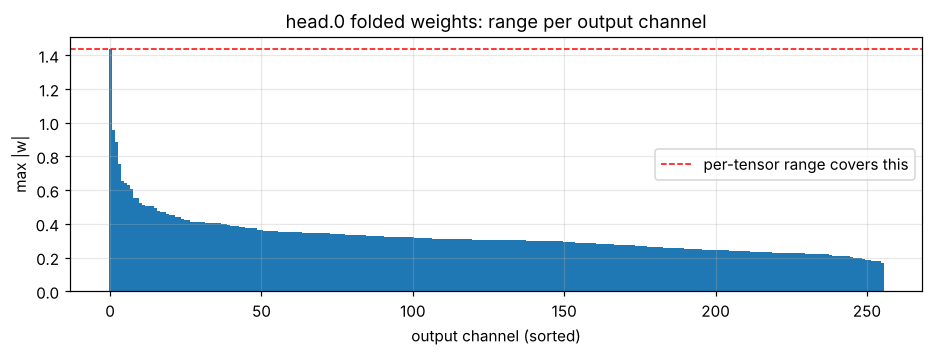

largest / smallest channel range: 8.4x -> the smallest channels get ~3.1 fewer effective bits with a per-tensor scale


In [5]:
folded = {}
for name, blk in [("local.0", model.local[0]), ("local.1", model.local[1]), ("glob.0", model.glob[0]),
                  ("glob.1", model.glob[1]), ("head.0", model.head[0]), ("head.1", model.head[1])]:
    folded[name] = fold_bn(blk[0], blk[1])[0].squeeze(-1).numpy()
folded["head.3 (classifier)"] = model.head[3].weight.detach().squeeze(-1).numpy()

print(f"{'layer':22s} {'shape':>11s} {'per-tensor':>11s} {'per-channel':>12s}   (8-bit symmetric SQNR)")
for name, w in folded.items():
    pt = fake_quant(w, w.min(), w.max(), symmetric=True)
    pc = np.stack([fake_quant(r, r.min(), r.max(), symmetric=True) for r in w])
    print(f"{name:22s} {str(w.shape):>11s} {sqnr_db(w, pt):9.1f} dB {sqnr_db(w, pc):10.1f} dB")

w = folded["head.0"]
ranges = np.abs(w).max(1)
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(range(len(ranges)), np.sort(ranges)[::-1], width=1.0)
ax.axhline(ranges.max(), color="r", ls="--", lw=1, label="per-tensor range covers this")
ax.set_xlabel("output channel (sorted)"); ax.set_ylabel("max |w|"); ax.legend()
ax.set_title("head.0 folded weights: range per output channel")
plt.show()
print(f"largest / smallest channel range: {ranges.max() / ranges.min():.1f}x -> the smallest channels get "
      f"~{np.log2(ranges.max() / ranges.min()):.1f} fewer effective bits with a per-tensor scale")

## 5. Activations and calibration

Weights are known after training; activation ranges are not. **Calibration** runs representative data through the model and records
activation statistics, then picks a range per tensor. The choice trades **clipping error** (range too small) against **rounding error** (range too large).

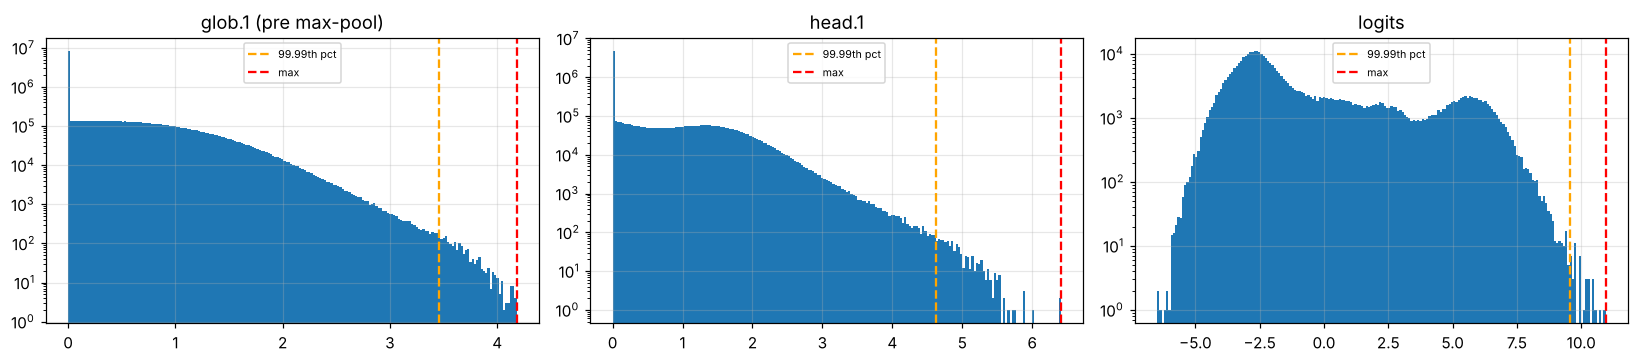

In [6]:
acts = {}
def hook(name):
    def f(_m, _i, out):
        acts.setdefault(name, []).append(out.detach().numpy().ravel())
    return f
handles = [model.glob[1].register_forward_hook(hook("glob.1 (pre max-pool)")),
           model.head[1].register_forward_hook(hook("head.1")),
           model.head[3].register_forward_hook(hook("logits"))]
calib = SyntheticScans("val", 32, N, augment_data=False)
with torch.no_grad():
    for i in range(len(calib)):
        model(calib[i][0][None])
for h in handles: h.remove()
acts = {k: np.concatenate(v) for k, v in acts.items()}

fig, axs = plt.subplots(1, 3, figsize=(15, 3.4))
for ax, (name, a) in zip(axs, acts.items()):
    ax.hist(a, bins=200, log=True)
    ax.axvline(np.percentile(a, 99.99), color="orange", ls="--", label="99.99th pct")
    ax.axvline(a.max(), color="r", ls="--", label="max")
    ax.set_title(name); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

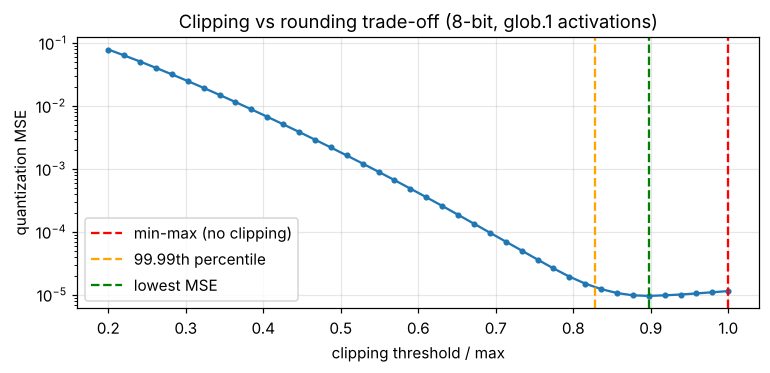

MSE at min-max: 1.15e-05   best MSE: 9.65e-06 at 0.90 x max
Caveat: lowest MSE is not always best for accuracy. This layer feeds a max-pool, which *selects the largest values*,
so clipping them can hurt more than MSE suggests. Check the percentile variant in sections 7-8.


In [7]:
a = acts["glob.1 (pre max-pool)"]
sample = np.random.default_rng(0).choice(a, 200_000, replace=False)
clips = np.linspace(0.2, 1.0, 40) * a.max()
mse = [np.mean((sample - fake_quant(sample, 0.0, c)) ** 2) for c in clips]
best = clips[int(np.argmin(mse))]

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(clips / a.max(), mse, "o-", ms=3)
ax.axvline(1.0, color="r", ls="--", label="min-max (no clipping)")
ax.axvline(np.percentile(a, 99.99) / a.max(), color="orange", ls="--", label="99.99th percentile")
ax.axvline(best / a.max(), color="g", ls="--", label="lowest MSE")
ax.set_xlabel("clipping threshold / max"); ax.set_ylabel("quantization MSE"); ax.set_yscale("log"); ax.legend()
ax.set_title("Clipping vs rounding trade-off (8-bit, glob.1 activations)")
plt.show()
print(f"MSE at min-max: {mse[-1]:.2e}   best MSE: {min(mse):.2e} at {best/a.max():.2f} x max")
print("Caveat: lowest MSE is not always best for accuracy. This layer feeds a max-pool, which *selects the largest values*,")
print("so clipping them can hurt more than MSE suggests. Check the percentile variant in sections 7-8.")

## 6. Reading a quantized (QDQ) ONNX graph

ONNX Runtime's quantizer writes a **QDQ** graph: every quantized tensor `T` becomes `T → QuantizeLinear → DequantizeLinear → consumer`.
The scale and zero-point live as initializers next to these nodes. A runtime (ORT, TensorRT, QNN…) recognizes the pattern
`DQ → Conv → Q` and replaces it with an integer convolution.

In [8]:
from collections import Counter
from onnx import numpy_helper

qpath = ONNX_DIR / "pointnet_seg_w8a8_perchannel.onnx"
qm = onnx.load(str(qpath))
init = {t.name: numpy_helper.to_array(t) for t in qm.graph.initializer}
print("op counts:", dict(Counter(n.op_type for n in qm.graph.node)))
print()
print(f"{'quantized tensor':45s} {'dtype':6s} {'scale shape':>12s} {'scale (first)':>14s} {'zero_point':>10s}")
for n in qm.graph.node:
    if n.op_type == "QuantizeLinear":
        s, zp = init[n.input[1]], init[n.input[2]]
        kind = "per-channel" if s.size > 1 else ""
        print(f"{n.input[0][:45]:45s} {str(zp.dtype):6s} {str(s.shape):>12s} {float(s.ravel()[0]):14.6f} {int(zp.ravel()[0]):10d} {kind}")
for n in qm.graph.node:
    if n.op_type == "DequantizeLinear" and n.input[0] in init and init[n.input[0]].ndim == 3:
        w, s = init[n.input[0]], init[n.input[1]]
        print(f"\nexample weight: {n.input[0]}  int8 {w.shape}, {s.size} per-channel scales -> stored as int8, dequantized on the fly")
        break

op counts: {'DequantizeLinear': 24, 'QuantizeLinear': 10, 'Conv': 7, 'ReduceMax': 1, 'Expand': 1, 'Concat': 1}

quantized tensor                              dtype   scale shape  scale (first) zero_point
points                                        uint8            ()       0.009320        128 
relu                                          uint8            ()       0.017369          0 
relu_1                                        uint8            ()       0.023260          0 
relu_2                                        uint8            ()       0.023982          0 
relu_3                                        uint8            ()       0.017615          0 
expand                                        uint8            ()       0.017615          0 
cat                                           uint8            ()       0.023260          0 
relu_4                                        uint8            ()       0.021266          0 
relu_5                                        uint8 

**Note:** the activation tensors are quantized after `Relu`, and the quantizer merged each `Conv → Relu` pair: the integer kernel
applies ReLU by clamping to the zero-point, so ReLU is free after quantization.

## 7. Accuracy, size and latency of every variant

Latency is ONNX Runtime on your CPU, single thread, batch 1. On a laptop, int8 helps less than on an NPU, and W8A16 can even be slower
because ONNX Runtime's 16-bit QDQ path uses generic (contrib) kernels. On accelerators with native 16-bit support (e.g. Qualcomm HTP)
W8A16 is a common, fast choice. The accuracy comparison is what transfers.

model                    mIoU pole IoU noise IoU  p50 ms     KB
pytorch_fp32            0.828    0.679     0.673     nan       
onnx_fp32               0.828    0.679     0.673    5.64    656
onnx_w8a16              0.827    0.677     0.672    6.85    182
onnx_w8a8_entropy       0.827    0.675     0.673    1.94    197
onnx_w8a8_head_fp32     0.826    0.675     0.671    2.10    199
onnx_w8a8_percentile    0.826    0.673     0.674    2.00    197
onnx_w8a8_perchannel    0.827    0.675     0.673    1.91    197
onnx_w8a8_pertensor     0.824    0.676     0.661    2.00    186


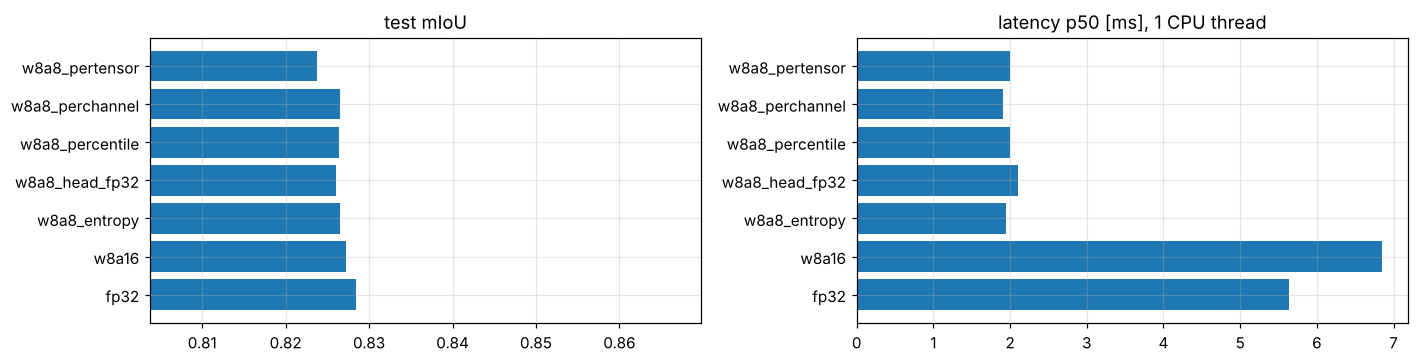

In [9]:
import csv
from src.evaluate import eval_onnx, eval_torch, benchmark

results_csv = Path("outputs/results.csv")
if results_csv.exists():
    rows = list(csv.DictReader(open(results_csv)))
else:
    rows = [{"model": "pytorch_fp32", **eval_torch(str(CKPT), 50, N)}]
    for p in sorted(ONNX_DIR.glob("pointnet_seg_*.onnx")):
        if p.stem.endswith("_prep"):
            continue
        rows.append({"model": p.stem.replace("pointnet_seg_", "onnx_"), **eval_onnx(str(p), 50, N), **benchmark(str(p), N),
                     "size_kb": round(p.stat().st_size / 1024)})

print(f"{'model':22s} {'mIoU':>6s} {'pole IoU':>8s} {'noise IoU':>9s} {'p50 ms':>7s} {'KB':>6s}")
for r in rows:
    f = lambda k: float(r[k]) if r.get(k) not in (None, "") else float("nan")
    print(f"{r['model']:22s} {f('mIoU'):6.3f} {f('IoU_pole'):8.3f} {f('IoU_noise'):9.3f} {f('p50_ms'):7.2f} {str(r.get('size_kb', '')):>6s}")

onnx_rows = [r for r in rows if r.get("p50_ms") not in (None, "")]
fig, axs = plt.subplots(1, 2, figsize=(13, 3.4))
names = [r["model"].replace("onnx_", "") for r in onnx_rows]
axs[0].barh(names, [float(r["mIoU"]) for r in onnx_rows]); axs[0].set_xlim(min(float(r["mIoU"]) for r in onnx_rows) - 0.02, None)
axs[0].set_title("test mIoU")
axs[1].barh(names, [float(r["p50_ms"]) for r in onnx_rows]); axs[1].set_title("latency p50 [ms], 1 CPU thread")
plt.tight_layout(); plt.show()

## 8. Layer-by-layer: where does the error enter?

This is the debugging loop you'd run when a quantized model misbehaves on a device: run the float reference and the quantized
model on the same input, expose every intermediate tensor, and plot the SQNR per layer. A sudden drop points at the culprit.

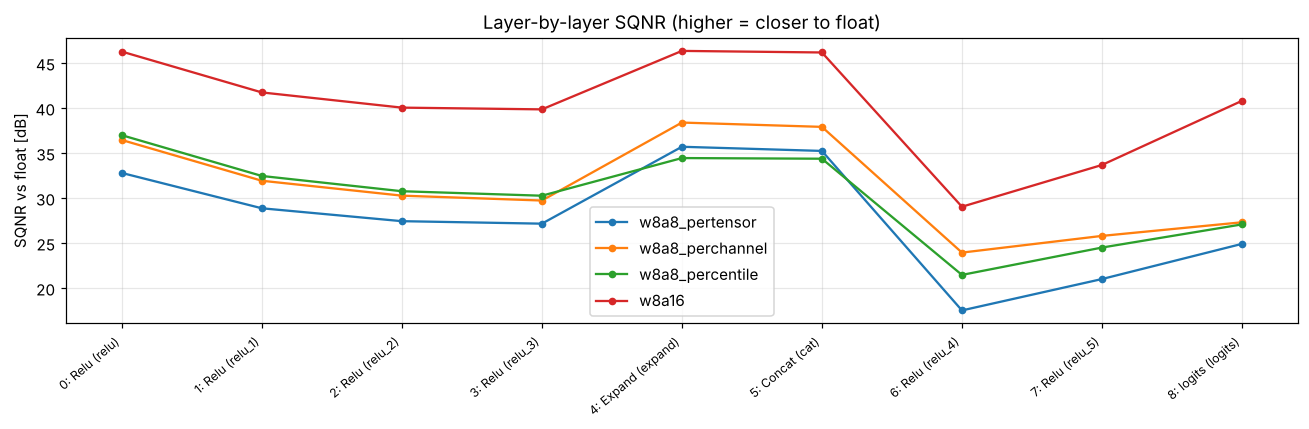

w8a8_pertensor   final logits SQNR  24.9 dB | biggest drop 17.7 dB at Relu 'relu_4'
w8a8_perchannel  final logits SQNR  27.3 dB | biggest drop 14.0 dB at Relu 'relu_4'
w8a8_percentile  final logits SQNR  27.1 dB | biggest drop 12.9 dB at Relu 'relu_4'
w8a16            final logits SQNR  40.8 dB | biggest drop 17.1 dB at Relu 'relu_4'


In [10]:
from src.compare_layers import compare
FP32_PREP = ONNX_DIR / "pointnet_seg_fp32_prep.onnx"
variants = ["w8a8_pertensor", "w8a8_perchannel", "w8a8_percentile", "w8a16"]
res = {v: compare(FP32_PREP, ONNX_DIR / f"pointnet_seg_{v}.onnx", n_scenes=6, n_points=N) for v in variants}

labels = [f"{r['idx']}: {r['op']} ({r['tensor']})" for r in res[variants[0]]]
fig, ax = plt.subplots(figsize=(12, 4))
for v, rows in res.items():
    ax.plot([r["sqnr_db"] for r in rows], "o-", ms=4, label=v)
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=40, ha="right", fontsize=8)
ax.set_ylabel("SQNR vs float [dB]"); ax.legend(); ax.set_title("Layer-by-layer SQNR (higher = closer to float)")
plt.tight_layout(); plt.show()

for v, rows in res.items():
    drops = [(rows[i]["sqnr_db"] - rows[i + 1]["sqnr_db"], rows[i + 1]) for i in range(len(rows) - 1)]
    d, r = max(drops, key=lambda t: t[0])
    print(f"{v:16s} final logits SQNR {rows[-1]['sqnr_db']:5.1f} dB | biggest drop {d:4.1f} dB at {r['op']} '{r['tensor']}'")

### How to read the plot

* **Tensor index → layer:** `relu`, `relu_1` = `local.0`, `local.1`; `relu_2`, `relu_3` = `glob.0`, `glob.1`; `expand` = the global
  feature after max-pool; `cat` = local + global concatenated; `relu_4`, `relu_5` = `head.0`, `head.1`; `logits` = classifier output.
* **Error accumulates with depth** through the conv stack: every quantized layer adds noise on top of what it receives.
* **The max-pool is forgiving**: SQNR goes *up* at `expand`, because only the largest value per channel survives and
  rounding noise is small relative to it. Percentile calibration hurts exactly here: it clips those largest values.
* **The head after the concat is the weakest point**: `head.0` mixes 320 inputs from two different sources, and both are quantized
  with one shared scale at the `Concat`.
* **Per-channel weights** beat per-tensor at every conv; **W8A16** gains roughly 10-15 dB everywhere (more activation bits).
* **SQNR vs accuracy:** 25 dB at the logits barely moves the arg-max here, so mIoU hardly changes. Regression outputs (e.g.
  trajectories or distances in metres) are much more sensitive, which is why they often keep 16-bit activations or a float head.

## Things to try

1. Quantize a model trained on **raw metres** (edit `to_model_input` to skip `/ SCENE_RADIUS`, retrain, re-quantize). Compare intensity-driven classes.
2. Lower the calibration set to 4 scenes in `src/quantize.py`. Which layers lose SQNR first?
3. Add a variant that keeps `head.0` in float via `nodes_to_exclude`. Does the logits SQNR jump?
4. **QAT**: fine-tune with fake quantization (`torch.ao.quantization` or a hand-written straight-through estimator using the
   `fake_quant` above) and compare with PTQ at 4-bit weights.
5. Run `python -m src.pretrained_image_seg --image <photo>` and repeat section 8 on a MobileNetV3 with depthwise convs.